# Lab: generate faces with a convolutional VAE

**Data:** CelebA · **Images:** 64 × 64 RGB · **Default latent dimension:** 128

We adapt the architecture of [AntixK's VanillaVAE](https://github.com/AntixK/PyTorch-VAE/blob/master/models/vanilla_vae.py)
into a self-contained PyTorch notebook. We train an encoder and decoder, inspect reconstructions,
and finally **generate new face images by sampling latent vectors from a standard normal distribution**.
FID is intentionally left for a later lab.

By the end, you should be able to explain the two encoder heads, implement the reparameterization
step and KL penalty, and distinguish reconstruction from generation.

**Run guide.** Use a GPU runtime if available (in Colab: Runtime → Change runtime type → GPU).
Run the cells from top to bottom. The first download is large; prepare the data before class.
The default run uses 50,000 training images for 30 epochs. `QUICK_RUN=True` is a small execution
check, not a setting intended to produce convincing faces. Increase the training budget for a
more developed model. Training speed and image quality depend on the hardware and fitted model.

**This copy has no pretrained weights or precomputed face-generation results.** Its model and
training/evaluation pipeline were checked using synthetic tensors. Run the CelebA training cells
to obtain your own results; the final section displays and saves the generated faces.

## 1. Setup and experiment settings

The next cell installs only missing packages. It leaves an existing PyTorch installation in place.
If your local PyTorch/torchvision installations are incompatible, install a matching pair using
the [PyTorch installation instructions](https://pytorch.org/get-started/locally/).

In [2]:
import importlib.util
import subprocess
import sys

packages = ['torch', 'torchvision', 'numpy', 'pandas', 'matplotlib', 'tqdm', 'gdown']
missing = [name for name in packages if importlib.util.find_spec(name) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
else:
    print('All required packages are available.')

All required packages are available.


In [3]:
import json
import math
import random
import time
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
from tqdm.auto import tqdm

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.utils import make_grid, save_image


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
print('PyTorch:', torch.__version__, '| device:', device)
if device.type == 'cpu':
    print('CPU execution works, but training this face model will be slow. A GPU is recommended.')

PyTorch: 2.7.0 | device: mps


Keep `IMAGE_SIZE=64`: five downsampling blocks reduce 64 → 32 → 16 → 8 → 4 → 2.
The model matches the upstream channel sizes and default latent dimension. For this teaching
adaptation, the learning rate is 0.001 (upstream: 0.005), and the default training budget is smaller.
We retain the upstream KL coefficient of 0.00025 and exponential learning-rate decay of 0.95.
The loss section explains its scaling.

`LOAD_CHECKPOINT` lets you reuse a checkpoint produced by this notebook instead of training again.
Change `LATENT_DIM` to match that checkpoint. Each fresh run writes to a new output directory.

In [4]:
SEED = 42
QUICK_RUN = False
IMAGE_SIZE = 64
LATENT_DIM = 128                    # Try 32, 64, or 128 in separate runs.
CHANNELS = (32, 64, 128, 256, 512)
BATCH_SIZE = 64
LEARNING_RATE = 1e-3
LR_DECAY = 0.95
KLD_WEIGHT = 2.5e-4

EPOCHS = 3 if QUICK_RUN else 30
TRAIN_LIMIT = 5_000 if QUICK_RUN else 50_000   # None uses the full training split.
VAL_LIMIT = 1_000 if QUICK_RUN else 5_000
TEST_LIMIT = 1_000 if QUICK_RUN else 5_000
NUM_WORKERS = 0                    # Portable default; try 2 on a Colab/Linux GPU runtime.

DATA_SOURCE = 'torchvision'         # 'torchvision' or 'folder'; see Section 2.
DOWNLOAD = True
DATA_ROOT = Path('./data')
IMAGE_DIR = DATA_ROOT / 'celeba' / 'img_align_celeba'
PARTITION_FILE = DATA_ROOT / 'celeba' / 'list_eval_partition.txt'
LOAD_CHECKPOINT = None             # Example: Path('outputs/.../best_vae.pt')

SHOW_PROGRESS = True
SAVE_EVERY = 5                     # Save fixed-prior sample grids every 5 epochs.
SAMPLE_SEED = 2026
OUTPUT_ROOT = Path('./outputs')
RUN_DIR = OUTPUT_ROOT / f'celeba_vae_d{LATENT_DIM}_{datetime.now():%Y%m%d_%H%M%S_%f}'
RUN_DIR.mkdir(parents=True, exist_ok=False)

assert IMAGE_SIZE == 64
assert isinstance(LATENT_DIM, int) and LATENT_DIM > 0
assert len(CHANNELS) == 5 and all(c > 0 for c in CHANNELS)
assert KLD_WEIGHT > 0 and EPOCHS >= 1 and BATCH_SIZE >= 2
seed_everything(SEED)
print(f'd={LATENT_DIM}, epochs={EPOCHS}, training limit={TRAIN_LIMIT}, KL weight={KLD_WEIGHT}')
print('Outputs:', RUN_DIR.resolve())

d=128, epochs=30, training limit=50000, KL weight=0.00025
Outputs: /Users/xig16121/Desktop/Teaching/Special/code/pytorch/outputs/celeba_vae_d128_20261014_152906_191871


## 2. Load CelebA

**Option A — torchvision (default).** `datasets.CelebA` downloads the archive and annotations
using `gdown`. On later runs, it reuses the local files. The official train/valid/test partitions
are kept separate. Attribute labels are returned by the loader but are ignored by this unconditional VAE.

**Option B — existing image folder.** If automatic downloading fails, obtain the aligned/cropped
images from the [CelebA project](https://mmlab.ie.cuhk.edu.hk/projects/CelebA.html), extract them,
set `DATA_SOURCE='folder'`, and set `IMAGE_DIR` to the directory that directly contains the JPGs.
This also works with a mounted Colab/Drive or Kaggle dataset directory. Set `PARTITION_FILE` to
`list_eval_partition.txt` when available. The folder loader then uses the official splits. If that
file is absent, it explicitly creates and reports a seeded 80/10/10 **image-level** split; it does
not claim that identities are disjoint.

For a manually prepared *torchvision* layout, put `img_align_celeba/` and these five text files
under `DATA_ROOT/celeba/`: `list_attr_celeba.txt`, `identity_CelebA.txt`, `list_bbox_celeba.txt`,
`list_landmarks_align_celeba.txt`, and `list_eval_partition.txt`. Set `DOWNLOAD=False` afterward.
The folder option needs only the images (plus the partition file when available).

**Preprocessing.** Center-crop to 148 × 148 as in the reference, resize to 64 × 64, and normalize
pixel values from [0,1] to **[-1,1]** to match the decoder's Tanh output. This normalization is an
explicit adaptation. Only the training transform applies random horizontal flips; validation and
test transforms are deterministic. Selecting a subset saves training time, not initial download size.

In [5]:
train_transform = transforms.Compose([
    transforms.CenterCrop(148),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE), antialias=True),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])
eval_transform = transforms.Compose([
    transforms.CenterCrop(148),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE), antialias=True),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])


class FaceFiles(Dataset):
    def __init__(self, files, transform):
        self.files = list(files)
        self.transform = transform

    def __len__(self):
        return len(self.files)

    def __getitem__(self, index):
        with Image.open(self.files[index]) as image:
            x = self.transform(image.convert('RGB'))
        return x, 0                 # Dummy label: the VAE only uses x.


def folder_datasets(image_dir, partition_file, seed):
    files = sorted(p for p in Path(image_dir).iterdir()
                   if p.suffix.lower() in {'.jpg', '.jpeg', '.png'})
    if not files:
        raise FileNotFoundError(f'No images found directly inside {image_dir}. Check IMAGE_DIR.')
    if partition_file is not None and Path(partition_file).is_file():
        partition = pd.read_csv(partition_file, sep=r'\s+', header=None,
                                names=['filename', 'split'])
        split_by_name = dict(zip(partition.filename, partition.split))
        unknown = [p.name for p in files if p.name not in split_by_name]
        if unknown:
            raise ValueError(f'{len(unknown)} image names are absent from PARTITION_FILE.')
        groups = [[p for p in files if split_by_name[p.name] == s] for s in (0, 1, 2)]
        print('Folder data: using official CelebA partition assignments.')
    else:
        indices = np.random.default_rng(seed).permutation(len(files))
        cut1, cut2 = int(0.8 * len(files)), int(0.9 * len(files))
        groups = [[files[i] for i in idx]
                  for idx in np.split(indices, [cut1, cut2])]
        print('Folder data: seeded 80/10/10 image-level split (not the official partitions).')
    if any(len(g) == 0 for g in groups):
        raise ValueError('At least one split is empty. Check the image folder and partition file.')
    return (FaceFiles(groups[0], train_transform),
            FaceFiles(groups[1], eval_transform),
            FaceFiles(groups[2], eval_transform))


def subset_limit(dataset, limit, seed):
    if limit is None or limit >= len(dataset):
        return dataset
    if limit < 2:
        raise ValueError('Use a data limit of at least 2.')
    indices = np.random.default_rng(seed).choice(len(dataset), size=limit, replace=False)
    return Subset(dataset, indices.tolist())


def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)

In [6]:
if DATA_SOURCE == 'torchvision':
    try:
        train_full = datasets.CelebA(DATA_ROOT, split='train', download=DOWNLOAD,
                                     transform=train_transform, target_type='attr')
        val_full = datasets.CelebA(DATA_ROOT, split='valid', download=False,
                                   transform=eval_transform, target_type='attr')
        test_full = datasets.CelebA(DATA_ROOT, split='test', download=False,
                                    transform=eval_transform, target_type='attr')
    except (RuntimeError, OSError, ValueError, ImportError) as error:
        raise RuntimeError(
            'CelebA setup failed. Check the original error below. Google Drive quotas may '
            'require a manual download. See Option B above: extract the aligned images, '
            "set DATA_SOURCE='folder', and point IMAGE_DIR to the JPG directory."
        ) from error
elif DATA_SOURCE == 'folder':
    train_full, val_full, test_full = folder_datasets(IMAGE_DIR, PARTITION_FILE, SEED)
else:
    raise ValueError("DATA_SOURCE must be 'torchvision' or 'folder'.")

train_data = subset_limit(train_full, TRAIN_LIMIT, SEED)
val_data = subset_limit(val_full, VAL_LIMIT, SEED + 1)
test_data = subset_limit(test_full, TEST_LIMIT, SEED + 2)

loader_options = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
                      pin_memory=(device.type == 'cuda'), worker_init_fn=seed_worker,
                      persistent_workers=(NUM_WORKERS > 0))
train_loader = DataLoader(train_data, shuffle=True,
    generator=torch.Generator().manual_seed(SEED), **loader_options)
val_loader = DataLoader(val_data, shuffle=False,
    generator=torch.Generator().manual_seed(SEED + 1), **loader_options)
test_loader = DataLoader(test_data, shuffle=False,
    generator=torch.Generator().manual_seed(SEED + 2), **loader_options)

print(f'Train: {len(train_data):,}; validation: {len(val_data):,}; test: {len(test_data):,}')
print('No validation or test images are used for gradient updates.')

Downloading...
From (original): https://drive.google.com/uc?id=0B7EVK8r0v71pZjFTYXZWM3FlRnM
From (redirected): https://drive.usercontent.google.com/download?id=0B7EVK8r0v71pZjFTYXZWM3FlRnM&confirm=t&uuid=0a47a8af-4ec2-4f2c-b928-e0ac5aa09238
To: /Users/xig16121/Desktop/Teaching/Special/code/pytorch/data/celeba/img_align_celeba.zip
100%|██████████| 1.44G/1.44G [00:23<00:00, 60.5MB/s]
Downloading...
From: https://drive.google.com/uc?id=0B7EVK8r0v71pblRyaVFSWGxPY0U
To: /Users/xig16121/Desktop/Teaching/Special/code/pytorch/data/celeba/list_attr_celeba.txt
100%|██████████| 26.7M/26.7M [00:00<00:00, 51.1MB/s]
Downloading...
From: https://drive.google.com/uc?id=1_ee_0u7vcNLOfNLegJRHmolfH5ICW-XS
To: /Users/xig16121/Desktop/Teaching/Special/code/pytorch/data/celeba/identity_CelebA.txt
100%|██████████| 3.42M/3.42M [00:00<00:00, 24.3MB/s]
Downloading...
From: https://drive.google.com/uc?id=0B7EVK8r0v71pbThiMVRxWXZ4dU0
To: /Users/xig16121/Desktop/Teaching/Special/code/pytorch/data/celeba/list_bbox_

Train: 50,000; validation: 5,000; test: 5,000
No validation or test images are used for gradient updates.


Batch shape: (64, 3, 64, 64) | range: -1.0 1.0


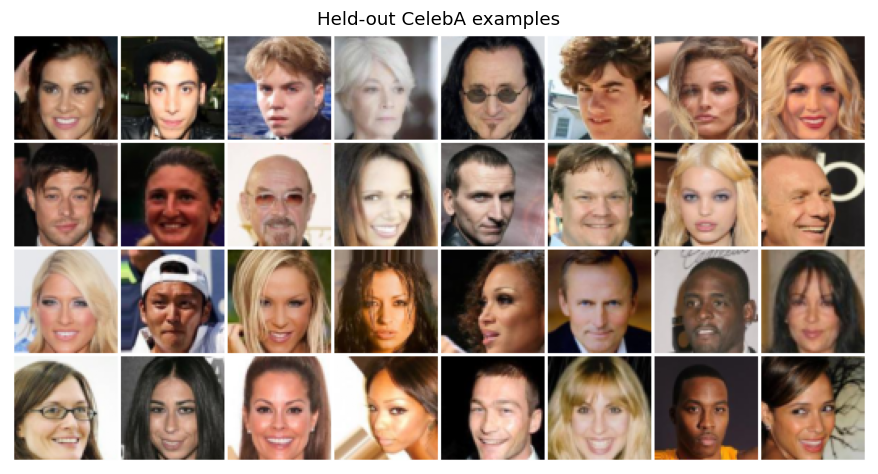

In [7]:
def to_01(images):
    return (images.detach().cpu() * 0.5 + 0.5).clamp(0, 1)


def show_faces(images, title, nrow=8, filename=None):
    images_01 = to_01(images)
    grid = make_grid(images_01, nrow=nrow, padding=2, pad_value=1)
    fig, ax = plt.subplots(figsize=(min(nrow, 8), 1.05 * math.ceil(len(images_01) / nrow)),
                            layout='constrained')
    ax.imshow(grid.permute(1, 2, 0).numpy())
    ax.set_axis_off()
    ax.set_title(title, fontsize=12)
    plt.show()
    if filename is not None:
        save_image(images_01, filename, nrow=nrow, padding=2, pad_value=1)


preview_images, _ = next(iter(val_loader))
print('Batch shape:', tuple(preview_images.shape), '| range:',
      float(preview_images.min()), float(preview_images.max()))
show_faces(preview_images[:32], 'Held-out CelebA examples')

## 3. The convolutional VAE

The encoder represents a diagonal Gaussian,
\[
q_\phi(z\mid x)=N\!\left(\mu_\phi(x),\operatorname{diag}\{\exp(\ell_\phi(x))\}\right),
\qquad \ell_\phi(x)=\log\sigma_\phi^2(x).
\]
The two heads each return $d$ numbers. The sampled latent vector has dimension **$d$, not $2d$**:
\[
\epsilon\sim N(0,I_d),\qquad
z=\mu_\phi(x)+\exp\{\ell_\phi(x)/2\}\odot\epsilon.
\]

| Stage | Shape, omitting batch dimension |
|---|---|
| Input | $3\times64\times64$ |
| Encoder blocks 1–5 | $32\times32\times32$, $64\times16\times16$, $128\times8\times8$, $256\times4\times4$, $512\times2\times2$ |
| Flatten | $2048$ |
| Two linear heads | $\mu\in\mathbb R^d$, $\ell\in\mathbb R^d$ |
| Sample | $z\in\mathbb R^d$ |
| Linear expansion + reshape | $512\times2\times2$ |
| Decoder upsampling blocks | $256\times4\times4$, $128\times8\times8$, $64\times16\times16$, $32\times32\times32$, $32\times64\times64$ |
| Final convolution + Tanh | $3\times64\times64$ |

Every encoder block is Conv2d → BatchNorm → LeakyReLU. Decoder blocks use transposed convolutions,
BatchNorm, and LeakyReLU. There are **no encoder–decoder skip connections**. The decoder receives
only $z$, which makes generation without an input image possible. The final image is interpreted
as the decoder's conditional mean. This is the same layer pattern as the reference VanillaVAE.

In [8]:
# Architecture adapted from AntixK/PyTorch-VAE, models/vanilla_vae.py.
# Original copyright: Anand Krishnamoorthy Subramanian, 2020. Apache-2.0.
# Changes: standalone nn.Module; dynamic reshape; explicit sampling controls;
# positive KL reporting and a plain PyTorch training/evaluation loop.

class VanillaVAE(nn.Module):
    def __init__(self, latent_dim=128, channels=(32, 64, 128, 256, 512)):
        super().__init__()
        if len(channels) != 5:
            raise ValueError('Use five encoder blocks for 64 x 64 inputs.')
        self.latent_dim = latent_dim
        self.feature_shape = (channels[-1], 2, 2)
        flat_dim = math.prod(self.feature_shape)

        encoder_blocks = []
        in_channels = 3
        for out_channels in channels:
            encoder_blocks.append(nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 3, stride=2, padding=1),
                nn.BatchNorm2d(out_channels),
                nn.LeakyReLU(negative_slope=0.01),
            ))
            in_channels = out_channels
        self.encoder = nn.Sequential(*encoder_blocks)
        self.fc_mu = nn.Linear(flat_dim, latent_dim)
        self.fc_logvar = nn.Linear(flat_dim, latent_dim)

        self.decoder_input = nn.Linear(latent_dim, flat_dim)
        decoder_channels = list(reversed(channels))
        decoder_blocks = []
        for cin, cout in zip(decoder_channels[:-1], decoder_channels[1:]):
            decoder_blocks.append(nn.Sequential(
                nn.ConvTranspose2d(cin, cout, 3, stride=2, padding=1, output_padding=1),
                nn.BatchNorm2d(cout),
                nn.LeakyReLU(negative_slope=0.01),
            ))
        self.decoder = nn.Sequential(*decoder_blocks)
        self.output_layer = nn.Sequential(
            nn.ConvTranspose2d(channels[0], channels[0], 3, stride=2,
                               padding=1, output_padding=1),
            nn.BatchNorm2d(channels[0]),
            nn.LeakyReLU(negative_slope=0.01),
            nn.Conv2d(channels[0], 3, 3, padding=1),
            nn.Tanh(),
        )

    def encode(self, x):
        features = self.encoder(x).flatten(start_dim=1)
        return self.fc_mu(features), self.fc_logvar(features)

    @staticmethod
    def reparameterize(mu, logvar, eps=None):
        if eps is None:
            eps = torch.randn_like(mu)
        return mu + torch.exp(0.5 * logvar) * eps

    def decode(self, z):
        features = self.decoder_input(z).reshape(-1, *self.feature_shape)
        return self.output_layer(self.decoder(features))

    def forward(self, x, sample=True):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar) if sample else mu
        return self.decode(z), mu, logvar

In [9]:
seed_everything(SEED)
model = VanillaVAE(LATENT_DIM, CHANNELS).to(device)
model.eval()
with torch.inference_mode():
    dummy = torch.zeros(2, 3, IMAGE_SIZE, IMAGE_SIZE, device=device)
    dummy_out, dummy_mu, dummy_logvar = model(dummy, sample=False)
assert dummy_mu.shape == dummy_logvar.shape == (2, LATENT_DIM)
assert dummy_out.shape == dummy.shape
print('Input:', tuple(dummy.shape))
print('mu:', tuple(dummy_mu.shape), '| log variance:', tuple(dummy_logvar.shape))
print('Reconstruction:', tuple(dummy_out.shape))
print(f'Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}')
del dummy, dummy_out, dummy_mu, dummy_logvar

Input: (2, 3, 64, 64)
mu: (2, 128) | log variance: (2, 128)
Reconstruction: (2, 3, 64, 64)
Trainable parameters: 3,937,635


## 4. Reconstruction loss and KL divergence

For image $i$, let $P=3\cdot64\cdot64=12288$. We use the reference's weighted MSE-plus-KL form:
\[
R_i=\frac1P\sum_{p=1}^P(x_{ip}-\hat x_{ip})^2,\qquad
K_i=\frac12\sum_{j=1}^d\left(\mu_{ij}^2+\exp(\ell_{ij})-1-\ell_{ij}\right),
\]
\[
\mathcal L=\frac1B\sum_{i=1}^B\big[R_i+\lambda K_i\big],
\qquad \lambda=\texttt{KLD\_WEIGHT}.
\]
During training, $\hat x_i$ is obtained from a reparameterized posterior draw. The KL term compares
$q_\phi(z\mid x_i)$ with the standard-normal prior. It is summed over latent coordinates and
averaged over images. **The reconstruction term is averaged over pixels**, so this coefficient
must be interpreted together with that reduction; switching from mean to sum changes the balance.
This weighted objective is not reported as a calibrated negative log-likelihood.

We use the **same fixed coefficient in training and validation** (the reference training wrapper
uses different coefficients in these two stages). Both terms are logged as nonnegative quantities.
MSE is computed on [-1,1] images; dividing it by 4 gives MSE on the original [0,1] scale.

In [10]:
def vae_loss(x_hat, x, mu, logvar, kld_weight):
    mse_per_image = (x_hat - x).square().flatten(start_dim=1).mean(dim=1)
    kl_per_image = 0.5 * (mu.square() + logvar.exp() - 1 - logvar).sum(dim=1)
    mse = mse_per_image.mean()
    kl = kl_per_image.mean()
    loss = mse + kld_weight * kl
    return {'loss': loss, 'mse': mse, 'kl': kl}

## 5. Train and select a checkpoint using validation data

Each epoch begins with `model.train()`. The optimizer updates both encoder and decoder through
the reparameterization step. Validation uses `model.eval()` and `torch.inference_mode()` so it
does not update weights or BatchNorm statistics. It still samples from the posterior when
evaluating the VAE objective. A fixed validation noise seed makes these comparisons less noisy
without consuming the random-number stream used for training.

The best validation objective selects `best_vae.pt`. We also save the latest weights, the complete
learning history, the experiment settings, and periodic grids from a fixed set of prior vectors.
The test split is evaluated only after checkpoint selection. If you interrupt training, completed
epochs already have saved checkpoints; set `LOAD_CHECKPOINT` to reuse one on the next run.
These checkpoints support inference/reuse, not an exact optimizer-state resume.

In [11]:
def train_one_epoch(model, loader, optimizer, kld_weight, epoch):
    model.train()
    totals = dict(loss=0.0, mse=0.0, kl=0.0)
    count = 0
    batches = tqdm(loader, desc=f'Epoch {epoch}', leave=False, disable=not SHOW_PROGRESS)
    for x, _ in batches:
        x = x.to(device, non_blocking=(device.type == 'cuda'))
        optimizer.zero_grad(set_to_none=True)
        x_hat, mu, logvar = model(x, sample=True)
        terms = vae_loss(x_hat, x, mu, logvar, kld_weight)
        if not torch.isfinite(terms['loss']):
            raise FloatingPointError('Non-finite loss. Check inputs and consider reducing LEARNING_RATE.')
        terms['loss'].backward()
        optimizer.step()
        count += len(x)
        for key in totals:
            totals[key] += float(terms[key].detach()) * len(x)
    return {key: value / count for key, value in totals.items()}


@torch.inference_mode()
def evaluate_vae(model, loader, kld_weight, noise_seed=1001):
    model.eval()
    noise_generator = torch.Generator(device='cpu').manual_seed(noise_seed)
    totals = dict(loss=0.0, mse=0.0, kl=0.0)
    count = 0
    for x, _ in loader:
        x = x.to(device, non_blocking=(device.type == 'cuda'))
        mu, logvar = model.encode(x)
        eps = torch.randn(mu.shape, generator=noise_generator).to(device)
        x_hat = model.decode(model.reparameterize(mu, logvar, eps=eps))
        terms = vae_loss(x_hat, x, mu, logvar, kld_weight)
        count += len(x)
        for key in totals:
            totals[key] += float(terms[key]) * len(x)
    result = {key: value / count for key, value in totals.items()}
    if not all(math.isfinite(value) for value in result.values()):
        raise FloatingPointError('Non-finite validation/test metric.')
    return result


@torch.inference_mode()
def sample_faces(model, num_faces=64, seed=2026):
    model.eval()
    generator = torch.Generator(device='cpu').manual_seed(seed)
    z = torch.randn(num_faces, model.latent_dim, generator=generator)
    z = z.to(next(model.parameters()).device)
    return model.decode(z).cpu()


def load_vae_checkpoint(path, model):
    checkpoint = torch.load(Path(path), map_location='cpu', weights_only=True)
    config = checkpoint['config']
    if config['latent_dim'] != model.latent_dim or config['channels'] != list(CHANNELS):
        raise ValueError('Checkpoint architecture differs. Match LATENT_DIM and CHANNELS, then rebuild model.')
    if config['image_size'] != IMAGE_SIZE or config['input_range'] != [-1, 1]:
        raise ValueError('Checkpoint preprocessing differs from this notebook.')
    model.load_state_dict(checkpoint['model_state'])
    model.to(device).eval()
    return checkpoint

In [12]:
run_config = {
    'latent_dim': LATENT_DIM, 'channels': list(CHANNELS), 'image_size': IMAGE_SIZE,
    'input_range': [-1, 1], 'crop_size': 148, 'kld_weight': KLD_WEIGHT,
    'learning_rate': LEARNING_RATE, 'lr_decay': LR_DECAY, 'seed': SEED,
    'epochs_requested': EPOCHS, 'batch_size': BATCH_SIZE, 'data_source': DATA_SOURCE,
    'train_size': len(train_data), 'val_size': len(val_data), 'test_size': len(test_data),
    'torch_version': str(torch.__version__),
}
(RUN_DIR / 'config.json').write_text(json.dumps(run_config, indent=2))

if LOAD_CHECKPOINT is not None:
    best_checkpoint = Path(LOAD_CHECKPOINT)
    checkpoint = load_vae_checkpoint(best_checkpoint, model)
    if not math.isclose(checkpoint['config']['kld_weight'], KLD_WEIGHT):
        raise ValueError('Set KLD_WEIGHT to the saved value for consistent evaluation.')
    history_df = pd.DataFrame(checkpoint['history'])
    print(f'Loaded checkpoint from epoch {checkpoint["epoch"]}; no training performed.')
else:
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=LR_DECAY)
    history = []
    best_val = float('inf')
    best_checkpoint = RUN_DIR / 'best_vae.pt'
    for epoch in range(1, EPOCHS + 1):
        started = time.perf_counter()
        lr_used = optimizer.param_groups[0]['lr']
        train_metrics = train_one_epoch(model, train_loader, optimizer, KLD_WEIGHT, epoch)
        val_metrics = evaluate_vae(model, val_loader, KLD_WEIGHT)
        row = {'epoch': epoch, 'lr': lr_used,
               **{f'train_{key}': value for key, value in train_metrics.items()},
               **{f'val_{key}': value for key, value in val_metrics.items()},
               'seconds': time.perf_counter() - started}
        history.append(row)
        checkpoint = {'model_state': model.state_dict(), 'config': run_config,
                       'epoch': epoch, 'val_loss': val_metrics['loss'], 'history': history}
        if val_metrics['loss'] < best_val:
            best_val = val_metrics['loss']
            torch.save(checkpoint, best_checkpoint)
        torch.save(checkpoint, RUN_DIR / 'last_vae.pt')
        history_df = pd.DataFrame(history)
        history_df.to_csv(RUN_DIR / 'history.csv', index=False)
        print(f'Epoch {epoch:03d}/{EPOCHS} | train loss {train_metrics["loss"]:.5f}'
              f' | val MSE {val_metrics["mse"]:.5f} | val KL {val_metrics["kl"]:.2f}'
              f' | val loss {val_metrics["loss"]:.5f} | {row["seconds"]:.1f}s', flush=True)
        if epoch == 1 or epoch % SAVE_EVERY == 0 or epoch == EPOCHS:
            samples = sample_faces(model, num_faces=64, seed=SAMPLE_SEED)
            save_image(to_01(samples), RUN_DIR / f'prior_samples_epoch_{epoch:03d}.png',
                       nrow=8, padding=2, pad_value=1)
        scheduler.step()
    print('Best checkpoint:', best_checkpoint.resolve())

Epoch 1:   0%|          | 0/782 [00:00<?, ?it/s]

Epoch 001/30 | train loss 0.09357 | val MSE 0.05315 | val KL 55.20 | val loss 0.06695 | 83.8s


Epoch 2:   0%|          | 0/782 [00:00<?, ?it/s]

Epoch 002/30 | train loss 0.06357 | val MSE 0.04876 | val KL 56.04 | val loss 0.06277 | 80.5s


Epoch 3:   0%|          | 0/782 [00:00<?, ?it/s]

...

Epoch 028/30 | train loss 0.04924 | val MSE 0.03335 | val KL 62.73 | val loss 0.04904 | 76.8s


Epoch 29:   0%|          | 0/782 [00:00<?, ?it/s]

Epoch 029/30 | train loss 0.04908 | val MSE 0.03341 | val KL 62.77 | val loss 0.04910 | 72.7s


Epoch 30:   0%|          | 0/782 [00:00<?, ?it/s]

Epoch 030/30 | train loss 0.04904 | val MSE 0.03323 | val KL 62.64 | val loss 0.04889 | 72.4s
Best checkpoint: /Users/xig16121/Desktop/Teaching/Special/code/pytorch/outputs/celeba_vae_d128_20261014_152906_191871/best_vae.pt


## 6. Inspect the learning curves

Training values average over parameter updates within an epoch; validation values use the model
at the end of that epoch. Read the reconstruction and KL curves together. A very small KL term
alone does not establish good generation: it can occur when the encoder barely uses the input.

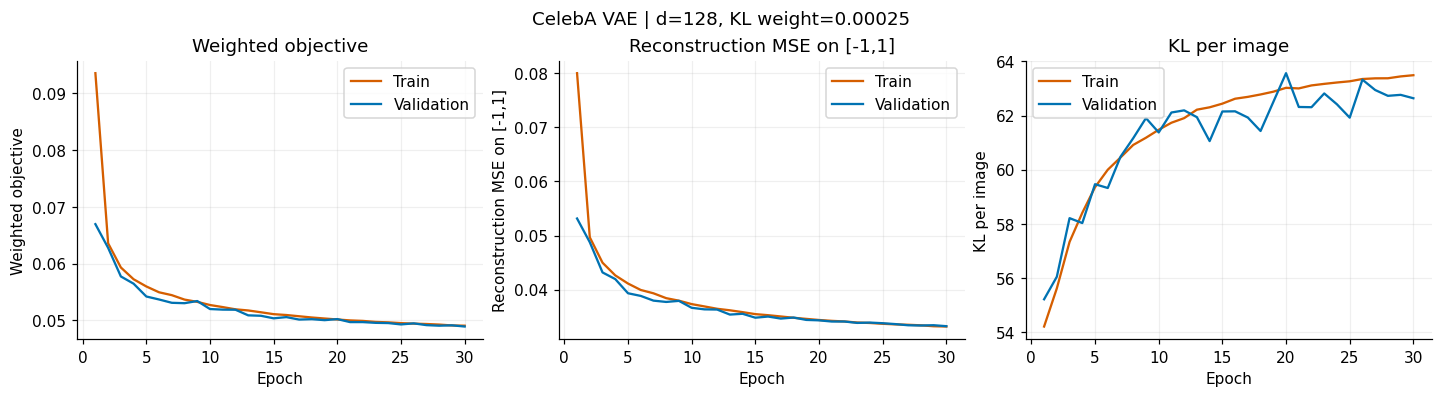

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), layout='constrained')
for ax, key, title in zip(axes, ['loss', 'mse', 'kl'],
                          ['Weighted objective', 'Reconstruction MSE on [-1,1]', 'KL per image']):
    ax.plot(history_df.epoch, history_df[f'train_{key}'], label='Train', color='#D55E00')
    ax.plot(history_df.epoch, history_df[f'val_{key}'], label='Validation', color='#0072B2')
    ax.set(xlabel='Epoch', ylabel=title, title=title)
    ax.grid(alpha=0.2)
    ax.legend()
fig.suptitle(f'CelebA VAE | d={LATENT_DIM}, KL weight={KLD_WEIGHT:g}')
fig.savefig(RUN_DIR / 'learning_curves.png', dpi=160, bbox_inches='tight')
plt.show()

## 7. Evaluate held-out faces and reconstruct them

Reload the checkpoint selected by validation. The test objective uses posterior sampling, just
as the training objective does. For a stable reconstruction display, use $z=\mu_\phi(x)$ instead.
We report the MSE for that deterministic choice separately; decoding the posterior mean is not
generally the same as averaging decoded posterior samples.

In [14]:
checkpoint = load_vae_checkpoint(best_checkpoint, model)
test_metrics = evaluate_vae(model, test_loader, KLD_WEIGHT, noise_seed=2002)


@torch.inference_mode()
def posterior_mean_mse(model, loader):
    model.eval()
    squared_error = 0.0
    num_values = 0
    for x, _ in loader:
        x = x.to(device)
        reconstruction, _, _ = model(x, sample=False)
        squared_error += (reconstruction - x).square().sum().item()
        num_values += x.numel()
    return squared_error / num_values / 4.0


test_summary = pd.DataFrame([{
    'Selected epoch': checkpoint['epoch'],
    'Test weighted objective': test_metrics['loss'],
    'Test posterior-sample MSE [0,1]': test_metrics['mse'] / 4.0,
    'Test KL per image': test_metrics['kl'],
    'Test posterior-mean reconstruction MSE [0,1]': posterior_mean_mse(model, test_loader),
}])
display(test_summary.T.rename(columns={0: 'Value'}))
test_summary.to_csv(RUN_DIR / 'test_metrics.csv', index=False)

,Value
Selected epoch,30.000000
Test weighted objective,0.048520
"Test posterior-sample MSE [0,1]",0.008229
Test KL per image,62.411708
"Test posterior-mean reconstruction MSE [0,1]",0.006806


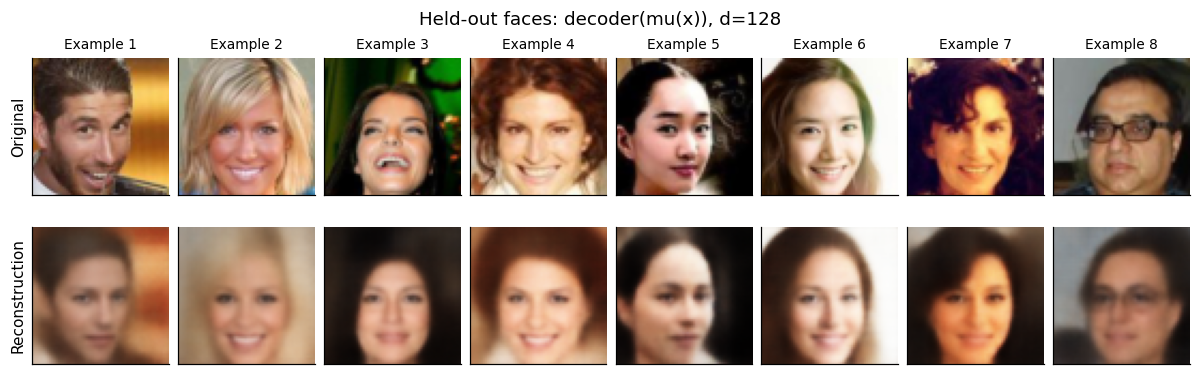

In [15]:
test_images, _ = next(iter(test_loader))
test_images = test_images[:8].to(device)
model.eval()
with torch.inference_mode():
    reconstructed, _, _ = model(test_images, sample=False)

original_01 = to_01(test_images)
reconstructed_01 = to_01(reconstructed)
n = len(original_01)
fig, axes = plt.subplots(2, n, figsize=(1.35 * n, 3.4), squeeze=False,
                          layout='constrained')
for col in range(n):
    for row, images in enumerate([original_01, reconstructed_01]):
        axes[row, col].imshow(images[col].permute(1, 2, 0).numpy())
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])
    axes[0, col].set_title(f'Example {col + 1}', fontsize=9)
axes[0, 0].set_ylabel('Original')
axes[1, 0].set_ylabel('Reconstruction')
fig.suptitle(f'Held-out faces: decoder(mu(x)), d={LATENT_DIM}')
fig.savefig(RUN_DIR / 'reconstructions.png', dpi=160, bbox_inches='tight')
plt.show()

## 8. Generate new face images

Now **do not supply an input face to the encoder**. Draw new latent vectors from the prior and
decode them:
\[
z^{(1)},\ldots,z^{(64)}\overset{\mathrm{iid}}\sim N(0,I_d),
\qquad \tilde x^{(i)}=g_\theta(z^{(i)}).
\]
As in the reference implementation, we display the decoder's mean image for each random latent
draw; we do not add observation noise to individual pixels. Use temperature 1 (the actual prior).
Change `NEW_FACE_SEED` to obtain a different reproducible batch. The faces below are generated
outputs, not reconstructions of a selected input. Sampling new vectors does not by itself prove
that the model has not memorized training examples.

If samples are blurry or poorly formed, inspect the learning curves and train longer or use more
training images before interpreting them. A quick execution check is not evidence of convergence.

**Discuss:** How do random generations differ from reconstructions? What changes when you use
$d=32,64,128$? What happens to reconstruction and generation when you increase the KL weight?

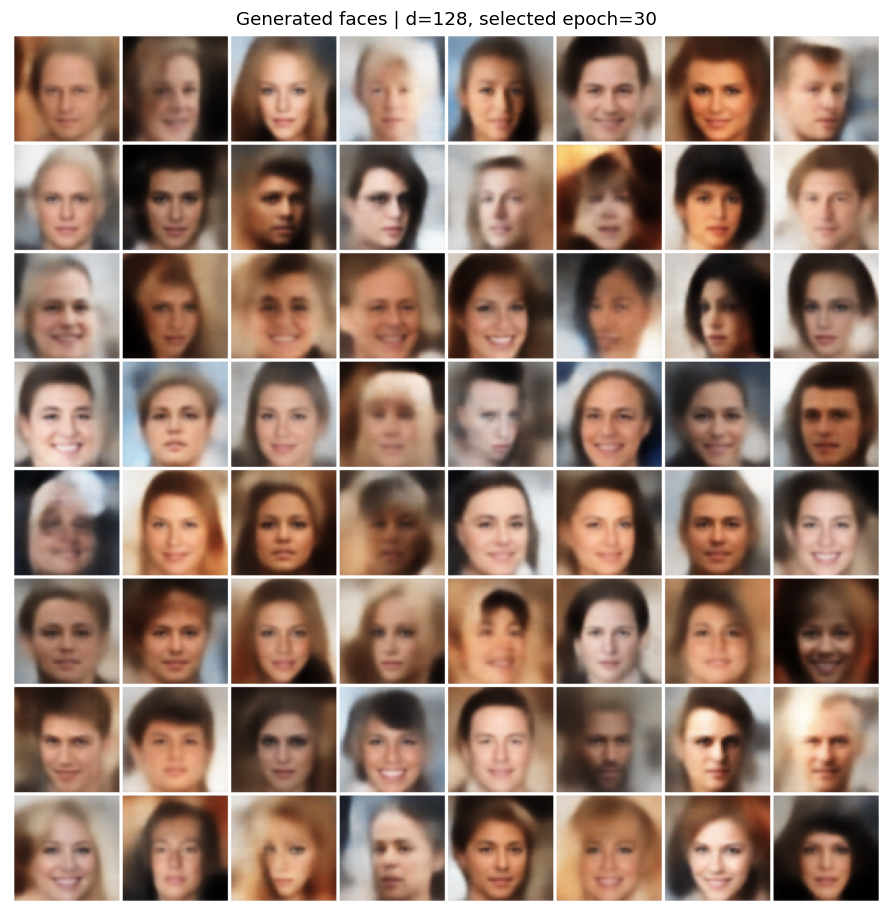

Generated grid: /Users/xig16121/Desktop/Teaching/Special/code/pytorch/outputs/celeba_vae_d128_20261014_152906_191871/generated_faces.png
Individual faces: /Users/xig16121/Desktop/Teaching/Special/code/pytorch/outputs/celeba_vae_d128_20261014_152906_191871/generated_faces_seed_2026


In [16]:
NEW_FACE_SEED = 2026
NUM_NEW_FACES = 64

# model contains the selected, trained weights from Section 7.
# sample_faces uses only fresh standard-normal latent vectors and the decoder.
new_faces = sample_faces(model, num_faces=NUM_NEW_FACES, seed=NEW_FACE_SEED)
show_faces(new_faces,
           f'Generated faces | d={model.latent_dim}, selected epoch={checkpoint["epoch"]}',
           nrow=8, filename=RUN_DIR / 'generated_faces.png')

# Save individual generated images as well as the grid.
face_dir = RUN_DIR / f'generated_faces_seed_{NEW_FACE_SEED}'
face_dir.mkdir(exist_ok=True)
for index, face in enumerate(to_01(new_faces)):
    save_image(face, face_dir / f'face_{index:03d}.png')
print('Generated grid:', (RUN_DIR / 'generated_faces.png').resolve())
print('Individual faces:', face_dir.resolve())

## References and adaptation notes

- [AntixK/PyTorch-VAE — VanillaVAE model](https://github.com/AntixK/PyTorch-VAE/blob/master/models/vanilla_vae.py)
- [Reference configuration](https://github.com/AntixK/PyTorch-VAE/blob/master/configs/vae.yaml)
- [Reference training wrapper](https://github.com/AntixK/PyTorch-VAE/blob/master/experiment.py)
- [Reference data transforms](https://github.com/AntixK/PyTorch-VAE/blob/master/dataset.py)
- [Torchvision CelebA documentation](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.CelebA.html)
- [CelebA dataset](https://mmlab.ie.cuhk.edu.hk/projects/CelebA.html)

**What is retained:** the five-block CNN architecture, the two Gaussian parameter heads,
reparameterization, transposed-convolution decoder, Tanh output, default latent dimension 128,
weighted MSE-plus-KL loss, and standard-normal prior sampling.

**What is changed:** standalone PyTorch loops; explicit [-1,1] input normalization; deterministic
validation preprocessing; separate validation/test sets; consistent training/validation KL weight;
positive KL logging; a lower learning rate; a smaller lab training budget; download/folder options;
checkpoint selection; and educational explanations. These are an adaptation, not a reproduction
of the repository's reported image quality.

The architecture implementation is adapted from work by **Anand Krishnamoorthy Subramanian (2020)**,
released under Apache License 2.0. The original notice and license are included below.

<details>
<summary>Apache 2.0 license and original attribution</summary>

Original copyright: Anand Krishnamoorthy Subramanian, 2020.
Original source: https://github.com/AntixK/PyTorch-VAE

Modifications for this notebook are described in the adaptation notes above.

```text

                                 Apache License
                           Version 2.0, January 2004
                        http://www.apache.org/licenses/

   TERMS AND CONDITIONS FOR USE, REPRODUCTION, AND DISTRIBUTION

   1. Definitions.

      "License" shall mean the terms and conditions for use, reproduction,
      and distribution as defined by Sections 1 through 9 of this document.

      "Licensor" shall mean the copyright owner or entity authorized by
      the copyright owner that is granting the License.

      "Legal Entity" shall mean the union of the acting entity and all
      other entities that control, are controlled by, or are under common
      control with that entity. For the purposes of this definition,
      "control" means (i) the power, direct or indirect, to cause the
      direction or management of such entity, whether by contract or
      otherwise, or (ii) ownership of fifty percent (50%) or more of the
      outstanding shares, or (iii) beneficial ownership of such entity.

      "You" (or "Your") shall mean an individual or Legal Entity
      exercising permissions granted by this License.

      "Source" form shall mean the preferred form for making modifications,
      including but not limited to software source code, documentation
      source, and configuration files.

      "Object" form shall mean any form resulting from mechanical
      transformation or translation of a Source form, including but
      not limited to compiled object code, generated documentation,
      and conversions to other media types.

      "Work" shall mean the work of authorship, whether in Source or
      Object form, made available under the License, as indicated by a
      copyright notice that is included in or attached to the work
      (an example is provided in the Appendix below).

      "Derivative Works" shall mean any work, whether in Source or Object
      form, that is based on (or derived from) the Work and for which the
      editorial revisions, annotations, elaborations, or other modifications
      represent, as a whole, an original work of authorship. For the purposes
      of this License, Derivative Works shall not include works that remain
      separable from, or merely link (or bind by name) to the interfaces of,
      the Work and Derivative Works thereof.

      "Contribution" shall mean any work of authorship, including
      the original version of the Work and any modifications or additions
      to that Work or Derivative Works thereof, that is intentionally
      submitted to Licensor for inclusion in the Work by the copyright owner
      or by an individual or Legal Entity authorized to submit on behalf of
      the copyright owner. For the purposes of this definition, "submitted"
      means any form of electronic, verbal, or written communication sent
      to the Licensor or its representatives, including but not limited to
      communication on electronic mailing lists, source code control systems,
      and issue tracking systems that are managed by, or on behalf of, the
      Licensor for the purpose of discussing and improving the Work, but
      excluding communication that is conspicuously marked or otherwise
      designated in writing by the copyright owner as "Not a Contribution."

      "Contributor" shall mean Licensor and any individual or Legal Entity
      on behalf of whom a Contribution has been received by Licensor and
      subsequently incorporated within the Work.

   2. Grant of Copyright License. Subject to the terms and conditions of
      this License, each Contributor hereby grants to You a perpetual,
      worldwide, non-exclusive, no-charge, royalty-free, irrevocable
      copyright license to reproduce, prepare Derivative Works of,
      publicly display, publicly perform, sublicense, and distribute the
      Work and such Derivative Works in Source or Object form.

   3. Grant of Patent License. Subject to the terms and conditions of
      this License, each Contributor hereby grants to You a perpetual,
      worldwide, non-exclusive, no-charge, royalty-free, irrevocable
      (except as stated in this section) patent license to make, have made,
      use, offer to sell, sell, import, and otherwise transfer the Work,
      where such license applies only to those patent claims licensable
      by such Contributor that are necessarily infringed by their
      Contribution(s) alone or by combination of their Contribution(s)
      with the Work to which such Contribution(s) was submitted. If You
      institute patent litigation against any entity (including a
      cross-claim or counterclaim in a lawsuit) alleging that the Work
      or a Contribution incorporated within the Work constitutes direct
      or contributory patent infringement, then any patent licenses
      granted to You under this License for that Work shall terminate
      as of the date such litigation is filed.

   4. Redistribution. You may reproduce and distribute copies of the
      Work or Derivative Works thereof in any medium, with or without
      modifications, and in Source or Object form, provided that You
      meet the following conditions:

      (a) You must give any other recipients of the Work or
          Derivative Works a copy of this License; and

      (b) You must cause any modified files to carry prominent notices
          stating that You changed the files; and

      (c) You must retain, in the Source form of any Derivative Works
          that You distribute, all copyright, patent, trademark, and
          attribution notices from the Source form of the Work,
          excluding those notices that do not pertain to any part of
          the Derivative Works; and

      (d) If the Work includes a "NOTICE" text file as part of its
          distribution, then any Derivative Works that You distribute must
          include a readable copy of the attribution notices contained
          within such NOTICE file, excluding those notices that do not
          pertain to any part of the Derivative Works, in at least one
          of the following places: within a NOTICE text file distributed
          as part of the Derivative Works; within the Source form or
          documentation, if provided along with the Derivative Works; or,
          within a display generated by the Derivative Works, if and
          wherever such third-party notices normally appear. The contents
          of the NOTICE file are for informational purposes only and
          do not modify the License. You may add Your own attribution
          notices within Derivative Works that You distribute, alongside
          or as an addendum to the NOTICE text from the Work, provided
          that such additional attribution notices cannot be construed
          as modifying the License.

      You may add Your own copyright statement to Your modifications and
      may provide additional or different license terms and conditions
      for use, reproduction, or distribution of Your modifications, or
      for any such Derivative Works as a whole, provided Your use,
      reproduction, and distribution of the Work otherwise complies with
      the conditions stated in this License.

   5. Submission of Contributions. Unless You explicitly state otherwise,
      any Contribution intentionally submitted for inclusion in the Work
      by You to the Licensor shall be under the terms and conditions of
      this License, without any additional terms or conditions.
      Notwithstanding the above, nothing herein shall supersede or modify
      the terms of any separate license agreement you may have executed
      with Licensor regarding such Contributions.

   6. Trademarks. This License does not grant permission to use the trade
      names, trademarks, service marks, or product names of the Licensor,
      except as required for reasonable and customary use in describing the
      origin of the Work and reproducing the content of the NOTICE file.

   7. Disclaimer of Warranty. Unless required by applicable law or
      agreed to in writing, Licensor provides the Work (and each
      Contributor provides its Contributions) on an "AS IS" BASIS,
      WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or
      implied, including, without limitation, any warranties or conditions
      of TITLE, NON-INFRINGEMENT, MERCHANTABILITY, or FITNESS FOR A
      PARTICULAR PURPOSE. You are solely responsible for determining the
      appropriateness of using or redistributing the Work and assume any
      risks associated with Your exercise of permissions under this License.

   8. Limitation of Liability. In no event and under no legal theory,
      whether in tort (including negligence), contract, or otherwise,
      unless required by applicable law (such as deliberate and grossly
      negligent acts) or agreed to in writing, shall any Contributor be
      liable to You for damages, including any direct, indirect, special,
      incidental, or consequential damages of any character arising as a
      result of this License or out of the use or inability to use the
      Work (including but not limited to damages for loss of goodwill,
      work stoppage, computer failure or malfunction, or any and all
      other commercial damages or losses), even if such Contributor
      has been advised of the possibility of such damages.

   9. Accepting Warranty or Additional Liability. While redistributing
      the Work or Derivative Works thereof, You may choose to offer,
      and charge a fee for, acceptance of support, warranty, indemnity,
      or other liability obligations and/or rights consistent with this
      License. However, in accepting such obligations, You may act only
      on Your own behalf and on Your sole responsibility, not on behalf
      of any other Contributor, and only if You agree to indemnify,
      defend, and hold each Contributor harmless for any liability
      incurred by, or claims asserted against, such Contributor by reason
      of your accepting any such warranty or additional liability.

   END OF TERMS AND CONDITIONS

   APPENDIX: How to apply the Apache License to your work.

      To apply the Apache License to your work, attach the following
      boilerplate notice, with the fields enclosed by brackets "[]"
      replaced with your own identifying information. (Don't include
      the brackets!)  The text should be enclosed in the appropriate
      comment syntax for the file format. We also recommend that a
      file or class name and description of purpose be included on the
      same "printed page" as the copyright notice for easier
      identification within third-party archives.

   Copyright [yyyy] [name of copyright owner]

   Licensed under the Apache License, Version 2.0 (the "License");
   you may not use this file except in compliance with the License.
   You may obtain a copy of the License at

       http://www.apache.org/licenses/LICENSE-2.0

   Unless required by applicable law or agreed to in writing, software
   distributed under the License is distributed on an "AS IS" BASIS,
   WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
   See the License for the specific language governing permissions and
   limitations under the License.

```

</details>